In [38]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA version: 13.0


In [39]:
%pip install -U "transformers>=4.57.0" datasets accelerate matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [40]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import Sam2Model, Sam2Processor

In [41]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [42]:
# ============================================================
# SAM2 + VegAnn FINE-TUNING — 30 EPOCHS
# ============================================================

import os
import torch

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

BATCH_SIZE = 1
NUM_EPOCHS = 30
LEARNING_RATE = 1e-4
NUM_WORKERS = 0

# Checkpoint directory
CHECKPOINT_DIR = "sam2_vegann_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Best model checkpoint
BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_sam2_vegann_mask_decoder_30.pt"
)

# Optional: save the final epoch as well
FINAL_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "final_sam2_vegann_mask_decoder_30.pt"
)

print("=" * 60)
print("SAM2 VEGANN TRAINING CONFIGURATION")
print("=" * 60)

print("Model:", MODEL_NAME)
print("Batch size:", BATCH_SIZE)
print("Number of epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Number of workers:", NUM_WORKERS)
print()
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Final checkpoint:", FINAL_MODEL_PATH)

print()
print("Checkpoint directory exists:", os.path.exists(CHECKPOINT_DIR))

SAM2 VEGANN TRAINING CONFIGURATION
Model: facebook/sam2.1-hiera-tiny
Batch size: 1
Number of epochs: 30
Learning rate: 0.0001
Number of workers: 0

Checkpoint directory: sam2_vegann_checkpoints
Best checkpoint: sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder_30.pt
Final checkpoint: sam2_vegann_checkpoints/final_sam2_vegann_mask_decoder_30.pt

Checkpoint directory exists: True


In [43]:
#Loading VegAnn
vegann = load_dataset("simonMadec/VegAnn")

print(vegann)
print("Columns:", vegann["train"].column_names)
print("Number of images:", len(vegann["train"]))


DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Number of images: 3775


In [44]:
#verify one VegAnn e.g 
sample = vegann["train"][0]

print("Keys:", sample.keys())

for key, value in sample.items():
    print(
        key,
        "| type:",
        type(value),
        "| size/shape:",
        getattr(value, "size", getattr(value, "shape", None))
    )

Keys: dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])
image | type: <class 'PIL.PngImagePlugin.PngImageFile'> | size/shape: (512, 512)
mask | type: <class 'PIL.PngImagePlugin.PngImageFile'> | size/shape: (512, 512)
System | type: <class 'str'> | size/shape: None
Orientation | type: <class 'str'> | size/shape: None
latitude | type: <class 'float'> | size/shape: None
longitude | type: <class 'float'> | size/shape: None
date | type: <class 'str'> | size/shape: None
LocAcc | type: <class 'int'> | size/shape: None
Species | type: <class 'str'> | size/shape: None
Owner | type: <class 'str'> | size/shape: None
Dataset-Name | type: <class 'str'> | size/shape: None
TVT-split1 | type: <class 'str'> | size/shape: None
TVT-split2 | type: <class 'str'> | size/shape: None
TVT-split3 | type: <class 'str'> | size/shape: None
TVT-split4 | type: <clas

In [45]:
#Set image and mask coloumn names 

column_names = vegann["train"].column_names

image_candidates = [
    "image",
    "images",
    "rgb",
    "img"
]

mask_candidates = [
    "mask",
    "masks",
    "label",
    "labels",
    "segmentation_mask",
    "annotation"
]

IMAGE_KEY = next(
    (key for key in image_candidates if key in column_names),
    None
)

MASK_KEY = next(
    (key for key in mask_candidates if key in column_names),
    None
)

print("Detected image column:", IMAGE_KEY)
print("Detected mask column:", MASK_KEY)

if IMAGE_KEY is None or MASK_KEY is None:
    raise ValueError(
        f"Could not automatically detect the columns. "
        f"Available columns: {column_names}"
    )

Detected image column: image
Detected mask column: mask


In [46]:
#Creating the val/train split 

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print("Training images:", len(train_hf))
print("Validation images:", len(val_hf))

Training images: 3020
Validation images: 755


In [47]:
#Converting masks to binary masks 0 for background and 1 for vegetation 
def prepare_binary_mask(mask):
    """
    Convert a PIL image, NumPy array or tensor into
    a binary uint8 NumPy mask containing only 0 and 1.
    """

    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    elif torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    else:
        mask = np.asarray(mask)

    # If the mask contains multiple channels, keep one channel.
    if mask.ndim == 3:
        mask = mask[..., 0]

    # Any positive value is treated as vegetation.
    mask = (mask > 0).astype(np.uint8)

    return mask

In [48]:
#Generating Bounding box from the mask 
def mask_to_box(mask, box_jitter=0):
    """
    Generate [x_min, y_min, x_max, y_max]
    from a binary vegetation mask.
    """

    y_indices, x_indices = np.where(mask > 0)

    if len(x_indices) == 0 or len(y_indices) == 0:
        return None

    x_min = int(x_indices.min())
    y_min = int(y_indices.min())
    x_max = int(x_indices.max())
    y_max = int(y_indices.max())

    height, width = mask.shape

    if box_jitter > 0:
        x_min -= random.randint(0, box_jitter)
        y_min -= random.randint(0, box_jitter)
        x_max += random.randint(0, box_jitter)
        y_max += random.randint(0, box_jitter)

    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(width - 1, x_max)
    y_max = min(height - 1, y_max)

    return [x_min, y_min, x_max, y_max]

In [49]:
#Cgecking for empty boxes -> better to exclude emoty masks as Bounding box cant be 
# created for an image that has no vegetataion e.g. soil only 
def count_empty_masks(hf_dataset):
    empty_count = 0

    for item in hf_dataset:
        mask = prepare_binary_mask(item[MASK_KEY])

        if mask.sum() == 0:
            empty_count += 1

    return empty_count


train_empty = count_empty_masks(train_hf)
val_empty = count_empty_masks(val_hf)

print("Empty training masks:", train_empty)
print("Empty validation masks:", val_empty)



Empty training masks: 54
Empty validation masks: 9


In [50]:
#Create the SAM2 VegAnn dataset class 
""" for every image the class returns 
RGB image, GT binary mask, GT vegetation boc and orignal dataset index"""
class VegAnnSAM2Dataset(Dataset):
    def __init__(
        self,
        hf_dataset,
        image_key,
        mask_key,
        training=False,
        box_jitter=0,
        skip_empty=True
    ):
        self.hf_dataset = hf_dataset
        self.image_key = image_key
        self.mask_key = mask_key
        self.training = training
        self.box_jitter = box_jitter
        self.skip_empty = skip_empty

        self.valid_indices = []

        for index in range(len(hf_dataset)):
            item = hf_dataset[index]
            mask = prepare_binary_mask(item[self.mask_key])

            if self.skip_empty and mask.sum() == 0:
                continue

            self.valid_indices.append(index)

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, index):
        original_index = self.valid_indices[index]
        item = self.hf_dataset[original_index]

        image = item[self.image_key]

        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))

        image = image.convert("RGB")

        mask = prepare_binary_mask(item[self.mask_key])

        box = mask_to_box(
            mask,
            box_jitter=self.box_jitter if self.training else 0
        )

        if box is None:
            height, width = mask.shape
            box = [0, 0, width - 1, height - 1]

        return {
            "image": image,
            "mask": mask,
            "box": box,
            "index": original_index
        }

In [51]:
#Create Training and Validation datasets 

train_dataset = VegAnnSAM2Dataset(
    hf_dataset=train_hf,
    image_key=IMAGE_KEY,
    mask_key=MASK_KEY,
    training=True,
    box_jitter=10,
    skip_empty=True
)

val_dataset = VegAnnSAM2Dataset(
    hf_dataset=val_hf,
    image_key=IMAGE_KEY,
    mask_key=MASK_KEY,
    training=False,
    box_jitter=0,
    skip_empty=True
)

print("Usable training images:", len(train_dataset))
print("Usable validation images:", len(val_dataset))

Usable training images: 2966
Usable validation images: 746


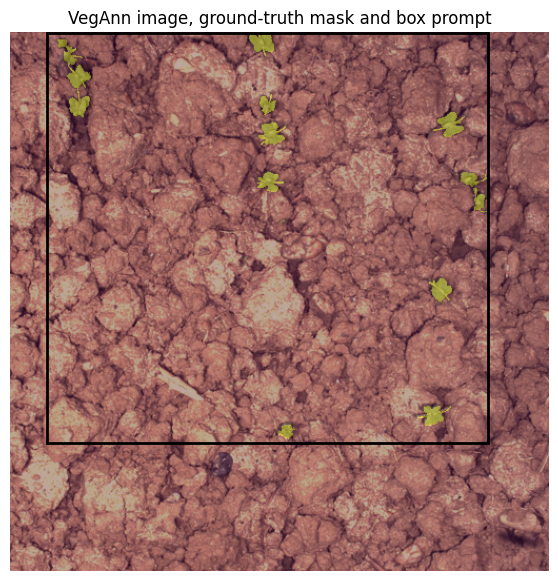

Image shape: (512, 512, 3)
Mask shape: (512, 512)
Box: [35, 0, 454, 390]
Vegetation pixels: 3352


In [52]:
#Visualize
example = train_dataset[0]

image = np.array(example["image"])
mask = example["mask"]
box = example["box"]

x_min, y_min, x_max, y_max = box

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.imshow(mask, alpha=0.35)

plt.gca().add_patch(
    plt.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )
)

plt.title("VegAnn image, ground-truth mask and box prompt")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Box:", box)
print("Vegetation pixels:", mask.sum())

In [53]:
#PIL images cannot be stacked directly by the standard DataLoader 
def sam2_collate_fn(batch):
    return {
        "images": [item["image"] for item in batch],
        "masks": [item["mask"] for item in batch],
        "boxes": [item["box"] for item in batch],
        "indices": [item["index"] for item in batch]
    }

In [54]:
#Create Dataloaders 
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=sam2_collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=sam2_collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 2966
Validation batches: 746


In [55]:
#Loading SAM2.1 and its processor 
processor = Sam2Processor.from_pretrained(MODEL_NAME)

model = Sam2Model.from_pretrained(MODEL_NAME)
model = model.to(device)

print("SAM2 loaded successfully")

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 loaded successfully


In [56]:
print (model)
print("\nTop-level SAM2 modules:")

for name, module in model.named_children():
    print(name, "->", type(module).__name__)


Sam2Model(
  (shared_image_embedding): Sam2PositionalEmbedding()
  (vision_encoder): Sam2VisionModel(
    (backbone): Sam2HieraDetModel(
      (patch_embed): Sam2PatchEmbeddings(
        (projection): Conv2d(3, 96, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
      )
      (blocks): ModuleList(
        (0): Sam2MultiScaleBlock(
          (layer_norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (attn): Sam2MultiScaleAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (proj): Linear(in_features=96, out_features=96, bias=True)
          )
          (layer_norm2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (mlp): Sam2FeedForward(
            (activation): GELUActivation()
            (proj_in): Linear(in_features=96, out_features=384, bias=True)
            (proj_out): Linear(in_features=384, out_features=96, bias=True)
            (layers): ModuleList()
          )
        )
    

In [57]:
#Freezing vision encoder, promot encoder and other SAM2 components except the mask decoder 
for parameter in model.parameters():
    parameter.requires_grad = False


mask_decoder = None

if hasattr(model, "mask_decoder"):
    mask_decoder = model.mask_decoder

elif hasattr(model, "sam_mask_decoder"):
    mask_decoder = model.sam_mask_decoder

else:
    for name, module in model.named_modules():
        if name.endswith("mask_decoder"):
            mask_decoder = module
            print("Detected mask decoder:", name)
            break


if mask_decoder is None:
    raise AttributeError(
        "Could not locate the SAM2 mask decoder. "
        "Please send me the output of Cell 19."
    )


for parameter in mask_decoder.parameters():
    parameter.requires_grad = True


total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_parameters / total_parameters:.4f}%"
)

Total parameters: 31,440,721
Trainable parameters: 4,215,109
Trainable percentage: 13.4065%


In [58]:
#Loss function 
""" BCE for pixel wise classification 
Dice for mask overlap combined gives pixel and region level supervision"""
bce_loss_fn = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(1)
    targets = targets.flatten(1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1.0 - dice.mean()


def combined_segmentation_loss(logits, targets):
    bce = bce_loss_fn(logits, targets)
    dice = dice_loss(logits, targets)

    total = 0.5 * bce + 0.5 * dice

    return total, bce, dice

In [59]:
#Helper for extracting SAM2 mask logits 
def extract_single_mask_logits(pred_masks):
    """
    Convert SAM2 output into [batch, height, width].
    Expected examples:
      [B, 1, 1, H, W]
      [B, 1, H, W]
      [B, H, W]
    """

    logits = pred_masks

    while logits.ndim > 3:
        logits = logits[:, 0]

    return logits


In [60]:
#processor resizes the iamages, transforms box coordinates, converts into Pytorch tensors
def prepare_sam2_batch(batch):
    images = batch["images"]
    masks = batch["masks"]
    boxes = batch["boxes"]

    
    input_boxes = [
        [box]
        for box in boxes
    ]

    inputs = processor(
        images=images,
        segmentation_maps=masks,
        input_boxes=input_boxes,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        if torch.is_tensor(value)
        else value
        for key, value in inputs.items()
    }

    return inputs

In [61]:
#Tesing one forward pass 
test_batch = next(iter(train_loader))
test_inputs = prepare_sam2_batch(test_batch)

print("Processor output keys:", test_inputs.keys())

for key, value in test_inputs.items():
    if torch.is_tensor(value):
        print(key, value.shape, value.dtype)




Processor output keys: dict_keys(['pixel_values', 'original_sizes', 'labels', 'input_boxes'])
pixel_values torch.Size([1, 3, 1024, 1024]) torch.float32
original_sizes torch.Size([1, 2]) torch.int64
labels torch.Size([1, 256, 256]) torch.int64
input_boxes torch.Size([1, 1, 4]) torch.float32


In [62]:
model.eval()

with torch.no_grad():
    image_embeddings = model.get_image_embeddings(
        test_inputs["pixel_values"]
    )

outputs = model(
    image_embeddings=image_embeddings,
    input_boxes=test_inputs["input_boxes"],
    multimask_output=False
)
print(type(outputs))
print(outputs)
print(outputs.keys())
logits = extract_single_mask_logits(outputs.pred_masks)

targets = test_inputs["labels"].float()

while targets.ndim > 3:
    targets = targets[:, 0]

targets = F.interpolate(
    targets.unsqueeze(1),
    size=logits.shape[-2:],
    mode="nearest"
).squeeze(1)

targets = (targets > 0).float()



print("Raw predicted masks:", outputs.pred_masks.shape)
print("Final logits:", logits.shape)
print("Targets:", targets.shape)

loss, bce, dice = combined_segmentation_loss(
    logits,
    targets
)

print("Test loss:", loss.item())
print("BCE component:", bce.item())
print("Dice component:", dice.item())

<class 'transformers.models.sam2.modeling_sam2.Sam2ImageSegmentationOutput'>
Sam2ImageSegmentationOutput(iou_scores=tensor([[[0.8621]]], device='cuda:0', grad_fn=<WhereBackward0>), pred_masks=tensor([[[[[0.5005, 0.5123, 0.5930,  ..., 0.8871, 1.4138, 0.8006],
           [0.7167, 0.5244, 1.1021,  ..., 1.8105, 1.4361, 0.8795],
           [0.3976, 1.2480, 1.2036,  ..., 1.6549, 1.3637, 0.9747],
           ...,
           [0.0692, 0.1827, 0.1842,  ..., 0.9645, 1.1824, 0.4781],
           [0.3143, 0.5451, 0.0970,  ..., 1.7407, 0.6107, 1.4241],
           [0.6635, 0.1741, 0.1519,  ..., 0.6870, 0.9511, 0.3069]]]]],
       device='cuda:0', grad_fn=<WhereBackward0>), object_score_logits=tensor([[[16.6607]]], device='cuda:0', grad_fn=<ViewBackward0>), image_embeddings=[tensor([[[[ 0.2660,  0.0872,  0.2294,  ...,  0.1670,  0.1382,  0.1056],
          [ 0.2480, -0.0006,  0.1510,  ...,  0.1140,  0.0138,  0.0838],
          [ 0.0835,  0.0866,  0.1338,  ...,  0.0498,  0.0655,  0.1406],
          ...,
 

In [63]:
#Defining the optimizer 
optimizer = torch.optim.AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Optimizer created")

Optimizer created


In [64]:
def update_metric_statistics(
    logits,
    targets,
    threshold=0.5,
    epsilon=1e-7
):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (predictions * targets).sum(dim=1)
    prediction_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    union = prediction_sum + target_sum - intersection

    per_image_iou = (
        intersection + epsilon
    ) / (
        union + epsilon
    )

    per_image_dice = (
        2 * intersection + epsilon
    ) / (
        prediction_sum + target_sum + epsilon
    )

    return {
        "per_image_iou_sum": per_image_iou.sum().item(),
        "per_image_dice_sum": per_image_dice.sum().item(),
        "intersection": intersection.sum().item(),
        "union": union.sum().item(),
        "prediction_sum": prediction_sum.sum().item(),
        "target_sum": target_sum.sum().item(),
        "num_images": targets.shape[0]
    }

In [65]:
loss, bce, dice = combined_segmentation_loss(
    logits,
    targets
)

print(loss)

loss.backward()

print("Backward successful!")

tensor(0.3320, device='cuda:0', grad_fn=<AddBackward0>)
Backward successful!


In [66]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):
    model.train()

    running_loss = 0.0
    running_bce = 0.0
    running_dice = 0.0

    for batch_index, batch in enumerate(loader):
        inputs = prepare_sam2_batch(batch)

        optimizer.zero_grad(set_to_none=True)

        # The vision encoder is frozen, so no gradients are stored.
        with torch.no_grad():
            image_embeddings = model.get_image_embeddings(
                inputs["pixel_values"]
            )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = model(
                image_embeddings=image_embeddings,
                input_boxes=inputs["input_boxes"],
                multimask_output=False
            )

            logits = extract_single_mask_logits(
                outputs.pred_masks
            )

            targets = inputs["labels"].float()

            while targets.ndim > 3:
                targets = targets[:, 0]

            targets = F.interpolate(
                targets.unsqueeze(1),
                size=logits.shape[-2:],
                mode="nearest"
            ).squeeze(1)

            targets = (targets > 0).float()

            loss, bce, dice = combined_segmentation_loss(
                logits,
                targets
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            mask_decoder.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        running_bce += bce.item()
        running_dice += dice.item()

        if (batch_index + 1) % 100 == 0:
            print(
                f"Batch {batch_index + 1}/{len(loader)} | "
                f"Loss: {running_loss / (batch_index + 1):.4f}"
            )

    number_of_batches = len(loader)

    return {
        "loss": running_loss / number_of_batches,
        "bce": running_bce / number_of_batches,
        "dice_loss": running_dice / number_of_batches
    }

In [67]:
#Defining validation 
@torch.no_grad()
def validate(
    model,
    loader,
    threshold=0.5
):
    model.eval()

    running_loss = 0.0

    metric_totals = {
        "per_image_iou_sum": 0.0,
        "per_image_dice_sum": 0.0,
        "intersection": 0.0,
        "union": 0.0,
        "prediction_sum": 0.0,
        "target_sum": 0.0,
        "num_images": 0
    }

    for batch in loader:
        inputs = prepare_sam2_batch(batch)

        image_embeddings = model.get_image_embeddings(
            inputs["pixel_values"]
        )

        outputs = model(
            image_embeddings=image_embeddings,
            input_boxes=inputs["input_boxes"],
            multimask_output=False
        )

        logits = extract_single_mask_logits(
            outputs.pred_masks
        )

        targets = inputs["labels"].float()

        while targets.ndim > 3:
            targets = targets[:, 0]

        targets = F.interpolate(
            targets.unsqueeze(1),
            size=logits.shape[-2:],
            mode="nearest"
        ).squeeze(1)

        targets = (targets > 0).float()

        loss, _, _ = combined_segmentation_loss(
            logits,
            targets
        )

        running_loss += loss.item()

        batch_metrics = update_metric_statistics(
            logits,
            targets,
            threshold=threshold
        )

        for key in metric_totals:
            metric_totals[key] += batch_metrics[key]

    epsilon = 1e-7

    mean_iou = (
        metric_totals["per_image_iou_sum"]
        / metric_totals["num_images"]
    )

    mean_dice = (
        metric_totals["per_image_dice_sum"]
        / metric_totals["num_images"]
    )

    global_iou = (
        metric_totals["intersection"] + epsilon
    ) / (
        metric_totals["union"] + epsilon
    )

    global_dice = (
        2 * metric_totals["intersection"] + epsilon
    ) / (
        metric_totals["prediction_sum"]
        + metric_totals["target_sum"]
        + epsilon
    )

    return {
        "loss": running_loss / len(loader),
        "mean_iou": mean_iou,
        "mean_dice": mean_dice,
        "global_iou": global_iou,
        "global_dice": global_dice
    }

In [68]:
DEBUG_BATCHES = 5

model.train()

for batch_index, batch in enumerate(train_loader):
    if batch_index >= DEBUG_BATCHES:
        break

    inputs = prepare_sam2_batch(batch)

    optimizer.zero_grad(set_to_none=True)

    with torch.no_grad():
        image_embeddings = model.get_image_embeddings(
            inputs["pixel_values"]
        )

    outputs = model(
        image_embeddings=image_embeddings,
        input_boxes=inputs["input_boxes"],
        multimask_output=False
    )

    logits = extract_single_mask_logits(
        outputs.pred_masks
    )

    targets = inputs["labels"].float()

    while targets.ndim > 3:
        targets = targets[:, 0]

    targets = F.interpolate(
        targets.unsqueeze(1),
        size=logits.shape[-2:],
        mode="nearest"
    ).squeeze(1)

    targets = (targets > 0).float()

    loss, _, _ = combined_segmentation_loss(
        logits,
        targets
    )

    loss.backward()
    optimizer.step()

    print(
        f"Debug batch {batch_index + 1} | "
        f"Loss: {loss.item():.4f}"
    )

Debug batch 1 | Loss: 0.6773
Debug batch 2 | Loss: 0.3465
Debug batch 3 | Loss: 0.1919
Debug batch 4 | Loss: 0.1110
Debug batch 5 | Loss: 0.2582


In [69]:
# ============================================================
# CHECK CURRENT SAM2 VARIABLES
# ============================================================

print("Variables containing 'sam2':")

for name in globals():
    if "sam2" in name.lower():
        print(" ", name)

Variables containing 'sam2':
  Sam2Model
  Sam2Processor
  VegAnnSAM2Dataset
  sam2_collate_fn
  prepare_sam2_batch


In [71]:
# ============================================================
# FULL SAM2 VEGANN TRAINING LOOP — 30 EPOCHS
# ============================================================

history = {
    "train_loss": [],
    "val_loss": [],
    "mean_iou": [],
    "mean_dice": [],
    "global_iou": [],
    "global_dice": []
}

best_mean_iou = -1.0

for epoch in range(NUM_EPOCHS):

    print("\n" + "=" * 60)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print("=" * 60)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    train_results = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        scaler=scaler
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    val_results = validate(
        model=model,
        loader=val_loader,
        threshold=0.5
    )

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    history["train_loss"].append(
        train_results["loss"]
    )

    history["val_loss"].append(
        val_results["loss"]
    )

    history["mean_iou"].append(
        val_results["mean_iou"]
    )

    history["mean_dice"].append(
        val_results["mean_dice"]
    )

    history["global_iou"].append(
        val_results["global_iou"]
    )

    history["global_dice"].append(
        val_results["global_dice"]
    )

    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print(
        f"Train Loss: "
        f"{train_results['loss']:.4f}"
    )

    print(
        f"Validation Loss: "
        f"{val_results['loss']:.4f}"
    )

    print(
        f"Mean IoU: "
        f"{100 * val_results['mean_iou']:.2f}%"
    )

    print(
        f"Mean Dice: "
        f"{100 * val_results['mean_dice']:.2f}%"
    )

    print(
        f"Global IoU: "
        f"{100 * val_results['global_iou']:.2f}%"
    )

    print(
        f"Global Dice: "
        f"{100 * val_results['global_dice']:.2f}%"
    )

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_results["mean_iou"] > best_mean_iou:

        best_mean_iou = val_results["mean_iou"]

        torch.save(
            {
                "epoch": epoch + 1,

                "model_name": MODEL_NAME,

                "mask_decoder_state_dict":
                    mask_decoder.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_mean_iou":
                    best_mean_iou,

                "history":
                    history
            },
            BEST_MODEL_PATH
        )

        print(
            "Saved new best checkpoint:",
            BEST_MODEL_PATH
        )

# ============================================================
# TRAINING COMPLETE
# ============================================================

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best Validation Mean IoU: "
    f"{100 * best_mean_iou:.2f}%"
)

print(
    "Checkpoint saved at:",
    BEST_MODEL_PATH
)

print(
    "Checkpoint exists:",
    os.path.exists(BEST_MODEL_PATH)
)

print("=" * 60)


Epoch 1/30
Batch 100/2966 | Loss: 0.2874
Batch 200/2966 | Loss: 0.2821
Batch 300/2966 | Loss: 0.2608
Batch 400/2966 | Loss: 0.2459
Batch 500/2966 | Loss: 0.2340
Batch 600/2966 | Loss: 0.2239
Batch 700/2966 | Loss: 0.2205
Batch 800/2966 | Loss: 0.2156
Batch 900/2966 | Loss: 0.2125
Batch 1000/2966 | Loss: 0.2072
Batch 1100/2966 | Loss: 0.2037
Batch 1200/2966 | Loss: 0.2028
Batch 1300/2966 | Loss: 0.1988
Batch 1400/2966 | Loss: 0.1968
Batch 1500/2966 | Loss: 0.1947
Batch 1600/2966 | Loss: 0.1918
Batch 1700/2966 | Loss: 0.1888
Batch 1800/2966 | Loss: 0.1876
Batch 1900/2966 | Loss: 0.1853
Batch 2000/2966 | Loss: 0.1834
Batch 2100/2966 | Loss: 0.1812
Batch 2200/2966 | Loss: 0.1808
Batch 2300/2966 | Loss: 0.1800
Batch 2400/2966 | Loss: 0.1796
Batch 2500/2966 | Loss: 0.1787
Batch 2600/2966 | Loss: 0.1771
Batch 2700/2966 | Loss: 0.1762
Batch 2800/2966 | Loss: 0.1752
Batch 2900/2966 | Loss: 0.1744
Train Loss: 0.1736
Validation Loss: 0.1411
Mean IoU: 85.29%
Mean Dice: 91.44%
Global IoU: 88.73%
G

In [73]:
# ============================================================
# CELL 1 — Imports and Device
# ============================================================

import os
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import Sam2Model, Sam2Processor

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA: 13.0
Device: cuda


In [ ]:
# ============================================================
#  Load VegAnn Dataset
# ============================================================

dataset = load_dataset("simonMadec/VegAnn")

print(dataset)

# Use the same 80/20 split as before
full_dataset = dataset["train"]

train_indices, val_indices = train_test_split(
    np.arange(len(full_dataset)),
    test_size=0.20,
    random_state=42
)

val_indices = list(val_indices)

print("Total images:", len(full_dataset))
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Total images: 3775
Training images: 3020
Validation images: 755


In [75]:
# ============================================================
#— VegAnn Helpers
# ============================================================

def get_image(sample):
    """
    Extract RGB image from a VegAnn sample.
    """
    image = sample["image"]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(sample):
    """
    Extract ground-truth segmentation mask.
    """
    mask = sample["mask"]

    if isinstance(mask, Image.Image):
        mask = np.array(mask)
    else:
        mask = np.array(mask)

    # Binary vegetation mask
    mask = (mask > 0).astype(np.uint8)

    return mask


# Test
test_sample = full_dataset[val_indices[0]]

test_image = get_image(test_sample)
test_mask = get_mask(test_sample)

print("Image size:", test_image.size)
print("Mask shape:", test_mask.shape)
print("Mask unique values:", np.unique(test_mask))

Image size: (512, 512)
Mask shape: (512, 512)
Mask unique values: [0 1]


In [78]:
import os
import torch
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# AGRICLIP WEIGHTS
# ============================================================

DINO_PATH = "/home/zahranadeem/thesis/agriclip_Zahra/weights/DINO-PT.pth"

ALIGNER_PATH = "/home/zahranadeem/thesis/agriclip_Zahra/weights/Agri_Dino_aligner_DDEF_CDEF.pth"


# ============================================================
# SAM2 CHECKPOINTS
# ============================================================

SAM2_30_PATH = (
    "/home/zahranadeem/thesis/agriclip_sam2/"
    "sam2_vegann_checkpoints/"
    "best_sam2_vegann_mask_decoder_30.pt"
)

# IMPORTANT:
# Replace this with your ACTUAL 20-epoch checkpoint path.
SAM2_20_PATH = (
    "/home/zahranadeem/thesis/agriclip_sam2/"
    "sam2_vegann_checkpoints/"
    "best_sam2_vegann_mask_decoder_20.pt"
)


# ============================================================
# PIPELINE SETTINGS
# ============================================================

K = 32

print("\nChecking files...")

print("DINO:", Path(DINO_PATH).exists())
print("Aligner:", Path(ALIGNER_PATH).exists())
print("SAM2 30:", Path(SAM2_30_PATH).exists())
print("SAM2 20:", Path(SAM2_20_PATH).exists())

Device: cuda
GPU: NVIDIA GeForce RTX 4090

Checking files...
DINO: True
Aligner: True
SAM2 30: False
SAM2 20: False


In [79]:
import torch
import torch.nn as nn

print("Loading DINO checkpoint...")

dino_checkpoint = torch.load(
    DINO_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded successfully.")

print("Checkpoint type:", type(dino_checkpoint))

if isinstance(dino_checkpoint, dict):
    print("Checkpoint keys:")
    print(list(dino_checkpoint.keys())[:30])

Loading DINO checkpoint...
Checkpoint loaded successfully.
Checkpoint type: <class 'dict'>
Checkpoint keys:
['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.0.conv3.weight', 'layer1.0.bn3.weight', 'layer1.0.bn3.bias', 'layer1.0.bn3.running_mean', 'layer1.0.bn3.running_var', 'layer1.0.bn3.num_batches_tracked', 'layer1.0.downsample.0.weight', 'layer1.0.downsample.1.weight', 'layer1.0.downsample.1.bias', 'layer1.0.downsample.1.running_mean', 'layer1.0.downsample.1.running_var', 'layer1.0.downsample.1.num_batches_tracked']


In [80]:
print("DINO model classes currently available:")

for name in ["DINO", "VisionTransformer", "vit_small", "vit_base"]:
    if name in globals():
        print("Found:", name)
        
print("Loading AgriCLIP aligner...")

aligner_checkpoint = torch.load(
    ALIGNER_PATH,
    map_location=device,
    weights_only=False
)

print("Aligner checkpoint loaded successfully.")

if isinstance(aligner_checkpoint, dict):
    print("Aligner checkpoint keys:")
    print(list(aligner_checkpoint.keys())[:30])

DINO model classes currently available:
Loading AgriCLIP aligner...
Aligner checkpoint loaded successfully.
Aligner checkpoint keys:
['b', 'W']


In [105]:
print(type(dino_model))

print("\nDINO attributes containing feature/layer:")
for name in dir(dino_model):
    if "feature" in name.lower() or "layer" in name.lower():
        print(name)

<class 'torchvision.models.resnet.ResNet'>

DINO attributes containing feature/layer:
_make_layer
_norm_layer
layer1
layer2
layer3
layer4


In [106]:
# ============================================================
# DINO RESNET SPATIAL FEATURE EXTRACTION
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Make absolutely sure DINO is on the correct device
dino_model = dino_model.to(device)
dino_model.eval()

print("DINO model:", type(dino_model))
print("Device:", device)


# ------------------------------------------------------------
# PREPROCESS IMAGE FOR DINO
# ------------------------------------------------------------

def preprocess_for_dino(image):

    # PIL -> numpy
    if not isinstance(image, np.ndarray):
        image = np.array(image)

    # numpy -> torch
    tensor = torch.from_numpy(image)

    # Convert to float
    tensor = tensor.float()

    # Convert 0-255 -> 0-1
    if tensor.max() > 1.0:
        tensor = tensor / 255.0

    # HWC -> CHW
    if tensor.ndim == 3:
        tensor = tensor.permute(2, 0, 1)

    # Add batch dimension
    if tensor.ndim == 3:
        tensor = tensor.unsqueeze(0)

    # Resize to standard ResNet/DINO input size
    tensor = F.interpolate(
        tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # Move to GPU
    tensor = tensor.to(device)

    # ImageNet normalization
    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=device
    ).view(1, 3, 1, 1)

    tensor = (tensor - mean) / std

    return tensor


# ------------------------------------------------------------
# EXTRACT RESNET LAYER4 SPATIAL FEATURES
# ------------------------------------------------------------

def extract_dino_patch_features(image):

    """
    Extract spatial DINO features from ResNet layer4.

    Returns:
        Tensor of shape:

        [num_patches, feature_dimension]

    For a standard ResNet with 224x224 input:

        7 x 7 = 49 patches

    """

    x = preprocess_for_dino(image)

    with torch.no_grad():

        # ResNet stem
        x = dino_model.conv1(x)
        x = dino_model.bn1(x)
        x = dino_model.relu(x)
        x = dino_model.maxpool(x)

        # ResNet stages
        x = dino_model.layer1(x)
        x = dino_model.layer2(x)
        x = dino_model.layer3(x)

        # IMPORTANT:
        # Stop here after layer4.
        # Do NOT apply avgpool or fc.
        x = dino_model.layer4(x)

    print("Raw layer4 feature map:", x.shape)

    # x:
    # [B, C, H, W]

    # Remove batch dimension
    x = x.squeeze(0)

    # [C, H, W] -> [H, W, C]
    x = x.permute(
        1,
        2,
        0
    )

    # [H, W, C] -> [H*W, C]
    features = x.reshape(
        -1,
        x.shape[-1]
    )

    features = features.float()

    return features


# ============================================================
# TEST
# ============================================================

features_test = extract_dino_patch_features(
    test_image
)

print()
print("DINO feature shape:", features_test.shape)
print("Number of patches:", features_test.shape[0])
print("Feature dimension:", features_test.shape[1])

DINO model: <class 'torchvision.models.resnet.ResNet'>
Device: cuda
Raw layer4 feature map: torch.Size([1, 2048, 7, 7])

DINO feature shape: torch.Size([49, 2048])
Number of patches: 49
Feature dimension: 2048


In [84]:
# ============================================================
# AgriCLIP LinearAligner
# ============================================================

class LinearAligner(nn.Module):
    def __init__(self, input_dim=2048, output_dim=512):
        super().__init__()

        self.linear = nn.Linear(
            input_dim,
            output_dim
        )

    def forward(self, x):
        return self.linear(x)


# Create aligner
vegann_aligner = LinearAligner(
    input_dim=2048,
    output_dim=512
).to(device)

ALIGNER_PATH = "vegann_aligner.pth"

aligner_checkpoint = torch.load(
    ALIGNER_PATH,
    map_location=device
)

if "state_dict" in aligner_checkpoint:
    aligner_state = aligner_checkpoint["state_dict"]
else:
    aligner_state = aligner_checkpoint

# Remove module prefix if present
clean_aligner_state = {}

for k, v in aligner_state.items():

    new_key = k

    if new_key.startswith("module."):
        new_key = new_key[len("module."):]

    clean_aligner_state[new_key] = v


missing, unexpected = vegann_aligner.load_state_dict(
    clean_aligner_state,
    strict=False
)

print("AgriCLIP LinearAligner loaded")
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

vegann_aligner.eval()

for param in vegann_aligner.parameters():
    param.requires_grad = False

AgriCLIP LinearAligner loaded
Missing keys: ['linear.weight', 'linear.bias']
Unexpected keys: ['b', 'W']


In [85]:
POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [88]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment


In [99]:
# Check the variables currently available in the notebook

for name in [
    "dino_model",
    "dino",
    "model",
    "agriclip_model",
    "aligner",
    "linear_aligner",
    "agri_model",
    "DINO_PATH",
    "ALIGNER_PATH",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj)}")

dino_model: <class 'torchvision.models.resnet.ResNet'>
model: <class 'transformers.models.sam2.modeling_sam2.Sam2Model'>
DINO_PATH: <class 'str'>
ALIGNER_PATH: <class 'str'>


In [101]:
# ============================================================
# CREATE TEXT-TO-CONCEPT MODEL
# ============================================================

text_to_concept = TextToConcept(
    model=dino_model,
    model_name="DINO"
)

print("TextToConcept created successfully!")
print("Model:", type(text_to_concept.model))
print("CLIP:", type(text_to_concept.clip_model))
print("Device:", text_to_concept.device)

TextToConcept created successfully!
Model: <class 'torchvision.models.resnet.ResNet'>
CLIP: <class 'TextToConcept.ClipZeroShot'>
Device: cuda


In [102]:
# ============================================================
# ENCODE POSITIVE AND NEGATIVE PROMPT SETS
# ============================================================

@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(embedding)

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(embedding)

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ============================================================
# POSITIVE PROMPTS
# ============================================================

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ============================================================
# NEGATIVE PROMPTS
# ============================================================

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


# ============================================================
# CHECK RESULTS
# ============================================================

print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])


In [108]:
# ============================================================
# ALIGN DINO FEATURES WITH AGRICLIP
# ============================================================

# Move the aligner to the correct device OUTSIDE the function
vegann_aligner = vegann_aligner.to(device)
vegann_aligner.eval()


def align_patch_features(features):
    """
    Project DINO layer4 patch features
    into the AgriCLIP embedding space.
    """

    features = features.to(device)

    with torch.no_grad():

        aligned = vegann_aligner(
            features
        )

        aligned = F.normalize(
            aligned,
            dim=-1
        )

    return aligned


# ============================================================
# TEST ALIGNMENT
# ============================================================

aligned_test = align_patch_features(
    features_test
)

print("DINO features:", features_test.shape)
print("Aligned features:", aligned_test.shape)
print("Number of patches:", aligned_test.shape[0])
print("Aligned dimension:", aligned_test.shape[1])

DINO features: torch.Size([49, 2048])
Aligned features: torch.Size([49, 512])
Number of patches: 49
Aligned dimension: 512


In [109]:
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Final vegetation embedding: torch.Size([512])


In [112]:
# ============================================================
# COMPUTE AGRICLIP PATCH-TEXT SIMILARITY SCORES
# ============================================================

with torch.no_grad():

    # Align the DINO patch features
    aligned_patches = align_patch_features(
        features_test
    )

    # Make sure vegetation embedding is on same device
    vegetation_embedding = (
        vegetation_embedding
        .to(device)
        .float()
    )

    # Normalize again for cosine similarity
    aligned_patches = F.normalize(
        aligned_patches,
        dim=-1
    )

    vegetation_embedding = F.normalize(
        vegetation_embedding,
        dim=0
    )

    # --------------------------------------------------------
    # Cosine similarity between every patch and vegetation text
    # --------------------------------------------------------

    patch_scores = (
        aligned_patches
        @ vegetation_embedding
    )


# ============================================================
# RESULTS
# ============================================================

print("Aligned patches shape:", aligned_patches.shape)
print("Vegetation embedding shape:", vegetation_embedding.shape)
print("Patch scores shape:", patch_scores.shape)

print(
    "Min:",
    patch_scores.min().item()
)

print(
    "Max:",
    patch_scores.max().item()
)

print(
    "Mean:",
    patch_scores.mean().item()
)

Aligned patches shape: torch.Size([49, 512])
Vegetation embedding shape: torch.Size([512])
Patch scores shape: torch.Size([49])
Min: 0.0013713673688471317
Max: 0.06417499482631683
Mean: 0.03556438907980919


In [113]:
# ============================================================
#  — Load SAM2
# ============================================================

SAM2_MODEL_NAME = "facebook/sam2.1-hiera-tiny"

processor = Sam2Processor.from_pretrained(
    SAM2_MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    SAM2_MODEL_NAME
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("SAM2 loaded")
print("Model:", SAM2_MODEL_NAME)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 loaded
Model: facebook/sam2.1-hiera-tiny


In [118]:
TOP_K =  32
scores = patch_scores.cpu().numpy()

sorted_indices = np.argsort(scores)[::-1]

topk_indices = sorted_indices[:TOP_K]

print("Top-K patch indices:")
print(topk_indices)

print("Scores:")
print(scores[topk_indices])

Top-K patch indices:
[46 45 44 43 42 47 48 14  7 21 15 31 11 10 28 25  8 35 38 36 39 29 23 22
 12 16 24 30  1 40  9 33]
Scores:
[0.06417499 0.06338388 0.06003309 0.05728889 0.05701761 0.05516597
 0.05482991 0.04478645 0.04442219 0.04256657 0.04112189 0.04111768
 0.04099797 0.04099279 0.040851   0.03980225 0.03920144 0.03834784
 0.03775088 0.0373979  0.03616532 0.0358801  0.03565174 0.03527307
 0.03403771 0.03341689 0.03330266 0.03320926 0.0331213  0.0326534
 0.03218058 0.03169016]


In [124]:
# ============================================================
# CONVERT TOP-K PATCHES INTO IMAGE-SPACE BOXES
# Works with NumPy or PIL images
# ============================================================

import numpy as np
from PIL import Image

PATCH_ROWS = 7
PATCH_COLS = 7

# ------------------------------------------------------------
# Check image
# ------------------------------------------------------------

print("Image type:", type(image))

if isinstance(image, np.ndarray):

    print("Image shape:", image.shape)

    # Expected: (H, W, C)
    if image.ndim == 3:
        H, W = image.shape[:2]

    # Grayscale: (H, W)
    elif image.ndim == 2:
        H, W = image.shape

    else:
        raise ValueError(
            f"Unexpected image shape: {image.shape}"
        )

elif isinstance(image, Image.Image):

    W, H = image.size

else:

    raise TypeError(
        f"Unsupported image type: {type(image)}"
    )

print("Image width :", W)
print("Image height:", H)

# ------------------------------------------------------------
# 7 × 7 spatial grid
# ------------------------------------------------------------

patch_h = H / PATCH_ROWS
patch_w = W / PATCH_COLS

print("Patch height:", patch_h)
print("Patch width :", patch_w)

# ------------------------------------------------------------
# Convert selected patch indices into boxes
# ------------------------------------------------------------

boxes = []

for idx in topk_indices:

    idx = int(idx)

    r = idx // PATCH_COLS
    c = idx % PATCH_COLS

    x1 = int(c * patch_w)
    y1 = int(r * patch_h)

    x2 = int((c + 1) * patch_w)
    y2 = int((r + 1) * patch_h)

    boxes.append(
        [x1, y1, x2, y2]
    )

boxes = np.array(
    boxes,
    dtype=np.int32
)

print("\nSelected patch indices:")
print(topk_indices)

print("\nPatch boxes:")
print(boxes)

print("\nNumber of selected patches:", len(boxes))

Image type: <class 'numpy.ndarray'>
Image shape: (512, 512, 3)
Image width : 512
Image height: 512
Patch height: 73.14285714285714
Patch width : 73.14285714285714

Selected patch indices:
[46 45 44 43 42 47 48 14  7 21 15 31 11 10 28 25  8 35 38 36 39 29 23 22
 12 16 24 30  1 40  9 33]

Patch boxes:
[[292 438 365 512]
 [219 438 292 512]
 [146 438 219 512]
 [ 73 438 146 512]
 [  0 438  73 512]
 [365 438 438 512]
 [438 438 512 512]
 [  0 146  73 219]
 [  0  73  73 146]
 [  0 219  73 292]
 [ 73 146 146 219]
 [219 292 292 365]
 [292  73 365 146]
 [219  73 292 146]
 [  0 292  73 365]
 [292 219 365 292]
 [ 73  73 146 146]
 [  0 365  73 438]
 [219 365 292 438]
 [ 73 365 146 438]
 [292 365 365 438]
 [ 73 292 146 365]
 [146 219 219 292]
 [ 73 219 146 292]
 [365  73 438 146]
 [146 146 219 219]
 [219 219 292 292]
 [146 292 219 365]
 [ 73   0 146  73]
 [365 365 438 438]
 [146  73 219 146]
 [365 292 438 365]]

Number of selected patches: 32


In [125]:
# ============================================================
# MERGE SELECTED PATCHES INTO ONE AGRICLIP BOX
# ============================================================

if len(boxes) == 0:
    raise ValueError("No selected patch boxes found.")

# ------------------------------------------------------------
# Bounding rectangle around all selected patches
# ------------------------------------------------------------

xmin = int(boxes[:, 0].min())
ymin = int(boxes[:, 1].min())

xmax = int(boxes[:, 2].max())
ymax = int(boxes[:, 3].max())

print("Original merged box:")
print([xmin, ymin, xmax, ymax])

# ------------------------------------------------------------
# Add margin
# ------------------------------------------------------------

margin = 25

xmin = max(0, xmin - margin)
ymin = max(0, ymin - margin)

xmax = min(W, xmax + margin)
ymax = min(H, ymax + margin)

merged_box = np.array(
    [xmin, ymin, xmax, ymax],
    dtype=np.int32
)

print("\nFinal AgriCLIP box:")
print(merged_box)

print("\nBox width :", xmax - xmin)
print("Box height:", ymax - ymin)

Original merged box:
[0, 0, 512, 512]

Final AgriCLIP box:
[  0   0 512 512]

Box width : 512
Box height: 512


In [129]:
# ============================================================
# LOAD FINE-TUNED SAM2 MASK DECODER — 30 EPOCHS
# ============================================================

import os
import torch

CHECKPOINT_30 = (
    "/home/zahranadeem/thesis/"
    "sam2_vegann_checkpoints/"
    "best_sam2_vegann_mask_decoder_30.pt"
)

print("=" * 60)
print("LOADING SAM2 30-EPOCH CHECKPOINT")
print("=" * 60)

print("Checkpoint:", CHECKPOINT_30)
print("Exists:", os.path.exists(CHECKPOINT_30))

if not os.path.exists(CHECKPOINT_30):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_30}"
    )

# Load checkpoint
checkpoint_30 = torch.load(
    CHECKPOINT_30,
    map_location=device,
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint_30))

# ------------------------------------------------------------
# Inspect checkpoint
# ------------------------------------------------------------

if isinstance(checkpoint_30, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint_30.keys():
        print("  -", key)

# ------------------------------------------------------------
# Extract MASK DECODER weights
# ------------------------------------------------------------

if "mask_decoder_state_dict" in checkpoint_30:

    print("\nUsing: mask_decoder_state_dict")

    mask_decoder.load_state_dict(
        checkpoint_30["mask_decoder_state_dict"]
    )

elif "model_state_dict" in checkpoint_30:

    print("\nUsing: model_state_dict")

    mask_decoder.load_state_dict(
        checkpoint_30["model_state_dict"]
    )

elif "state_dict" in checkpoint_30:

    print("\nUsing: state_dict")

    mask_decoder.load_state_dict(
        checkpoint_30["state_dict"]
    )

else:

    # Last possibility: checkpoint itself is the state dict
    print("\nCheckpoint does not contain a known wrapper key.")
    print("Attempting to load checkpoint directly...")

    mask_decoder.load_state_dict(
        checkpoint_30
    )

# ------------------------------------------------------------
# Evaluation mode
# ------------------------------------------------------------

mask_decoder = mask_decoder.to(device)
mask_decoder.eval()

print("\n" + "=" * 60)
print("SAM2 30-EPOCH MASK DECODER LOADED SUCCESSFULLY")
print("=" * 60)

if isinstance(checkpoint_30, dict):

    if "epoch" in checkpoint_30:
        print("Epoch:", checkpoint_30["epoch"])

    if "best_mean_iou" in checkpoint_30:
        print(
            "Best training IoU:",
            checkpoint_30["best_mean_iou"]
        )

print("Device:", device)

LOADING SAM2 30-EPOCH CHECKPOINT
Checkpoint: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder_30.pt
Exists: True

Checkpoint type: <class 'dict'>

Checkpoint keys:
  - epoch
  - model_name
  - mask_decoder_state_dict
  - optimizer_state_dict
  - best_mean_iou
  - history

Using: mask_decoder_state_dict

SAM2 30-EPOCH MASK DECODER LOADED SUCCESSFULLY
Epoch: 17
Best training IoU: 0.8730768586531401
Device: cuda


In [133]:
# ============================================================
# CELL: AgriCLIP + SAM2 | 30 Epoch SAM2 | VegAnn Val | K=32
# ============================================================

K = 32

print("=" * 70)
print("AGRICLIP + FINE-TUNED SAM2 EVALUATION")
print("=" * 70)
print("Dataset       : VegAnn validation")
print("Images        : 755")
print("SAM2          : Fine-tuned, 30 epochs")
print("Prompt method : AgriCLIP")
print("K             :", K)
print("=" * 70)



print("\nConfiguration ready.")


AGRICLIP + FINE-TUNED SAM2 EVALUATION
Dataset       : VegAnn validation
Images        : 755
SAM2          : Fine-tuned, 30 epochs
Prompt method : AgriCLIP
K             : 32

Configuration ready.


In [136]:
# ============================================================
# CELL 1: LOAD VEGANN DATASET
# ============================================================

from datasets import load_dataset

print("=" * 70)
print("LOADING VEGANN")
print("=" * 70)

vegann_dataset = load_dataset(
    "simonMadec/VegAnn"
)

print("\nDataset loaded successfully:")
print(vegann_dataset)

print("\nAvailable splits:")
print(vegann_dataset.keys())

LOADING VEGANN

Dataset loaded successfully:
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})

Available splits:
dict_keys(['train'])


In [140]:
# ============================================================
# CELL 2: CREATE VEGANN TRAIN / VALIDATION SPLIT
# ============================================================

from datasets import DatasetDict

print("=" * 70)
print("CREATING VEGANN VALIDATION SPLIT")
print("=" * 70)

full_vegann = vegann_dataset["train"]

print("Full VegAnn dataset:", len(full_vegann))

# ------------------------------------------------------------
# Create the same 80/20 split
# ------------------------------------------------------------

vegann_split = full_vegann.train_test_split(
    test_size=0.20,
    seed=42
)

vegann_train = vegann_split["train"]
vegann_val = vegann_split["test"]

print("\nTrain images:", len(vegann_train))
print("Validation images:", len(vegann_val))

assert len(vegann_val) == 755, (
    f"Expected 755 validation images, "
    f"but got {len(vegann_val)}"
)

print("\n✓ Validation split contains exactly 755 images")

CREATING VEGANN VALIDATION SPLIT
Full VegAnn dataset: 3775

Train images: 3020
Validation images: 755

✓ Validation split contains exactly 755 images


In [142]:
# ============================================================
# CELL 4: REGISTER DINO LAYER4 FEATURE HOOK
# ============================================================

print("=" * 70)
print("REGISTERING DINO LAYER4 HOOK")
print("=" * 70)

# Remove an old hook if one exists
if "dino_layer4_hook_handle" in globals():

    try:
        dino_layer4_hook_handle.remove()
        print("Removed previous DINO hook.")
    except Exception:
        pass


# Function to save layer4 output
def save_dino_layer4_features(module, input, output):

    dino_model.layer4_features = output


# Register hook
dino_layer4_hook_handle = dino_model.layer4.register_forward_hook(
    save_dino_layer4_features
)

print("✓ Hook registered on dino_model.layer4")
print("DINO layer4:", dino_model.layer4)

REGISTERING DINO LAYER4 HOOK
✓ Hook registered on dino_model.layer4
DINO layer4: Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(1024, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(1024, 2048, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (1): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (1): Bottleneck(
    (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=

In [143]:
# ============================================================
# : TEST DINO FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("TESTING DINO FEATURE EXTRACTION")
print("=" * 70)

# Get first VegAnn validation image
sample = vegann_val[0]

# ------------------------------------------------------------
# Find image
# ------------------------------------------------------------

if "image" in sample:
    test_image = sample["image"]

elif "img" in sample:
    test_image = sample["img"]

else:
    raise KeyError(
        f"Could not find image. Available keys: {sample.keys()}"
    )


# ------------------------------------------------------------
# Convert to PIL
# ------------------------------------------------------------

if isinstance(test_image, np.ndarray):

    test_image = Image.fromarray(test_image)

elif torch.is_tensor(test_image):

    test_image = test_image.detach().cpu()

    if test_image.ndim == 3:

        if test_image.shape[0] in [1, 3]:

            test_image = test_image.permute(
                1, 2, 0
            )

    test_image = test_image.numpy()

    if test_image.dtype != np.uint8:

        test_image = np.clip(
            test_image * 255,
            0,
            255
        ).astype(np.uint8)

    test_image = Image.fromarray(test_image)

elif not isinstance(test_image, Image.Image):

    test_image = Image.fromarray(
        np.array(test_image)
    )


test_image = test_image.convert("RGB")


print("Image type:", type(test_image))
print("Image size:", test_image.size)


# ------------------------------------------------------------
# Preprocess
# ------------------------------------------------------------

x = preprocess_for_dino(test_image)

x = x.to(device)


# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

with torch.no_grad():

    _ = dino_model(x)


# ------------------------------------------------------------
# Check layer4
# ------------------------------------------------------------

print("\nLayer4 feature attribute exists:",
      hasattr(dino_model, "layer4_features"))

features_test = dino_model.layer4_features

print(
    "Raw layer4 feature shape:",
    features_test.shape
)


# ------------------------------------------------------------
# Convert [B,C,H,W] -> [H*W,C]
# ------------------------------------------------------------

features_test = features_test.squeeze(0)

features_test = features_test.permute(
    1, 2, 0
)

features_test = features_test.reshape(
    -1,
    features_test.shape[-1]
)


print(
    "DINO patch feature shape:",
    features_test.shape
)

print(
    "Number of patches:",
    features_test.shape[0]
)

print(
    "Feature dimension:",
    features_test.shape[1]
)

print("=" * 70)

TESTING DINO FEATURE EXTRACTION
Image type: <class 'PIL.Image.Image'>
Image size: (512, 512)

Layer4 feature attribute exists: True
Raw layer4 feature shape: torch.Size([1, 2048, 7, 7])
DINO patch feature shape: torch.Size([49, 2048])
Number of patches: 49
Feature dimension: 2048


In [145]:
# ============================================================
# CELL 6: TEST AGRICLIP ALIGNMENT
# ============================================================

print("=" * 70)
print("TESTING AGRICLIP ALIGNMENT")
print("=" * 70)

features_test = features_test.to(device)

vegann_aligner.eval()

with torch.no_grad():

    aligned_test = vegann_aligner(
        features_test
    )

    aligned_test = F.normalize(
        aligned_test,
        dim=-1
    )


print(
    "DINO features:",
    features_test.shape
)

print(
    "Aligned AgriCLIP features:",
    aligned_test.shape
)

print(
    "Vegetation embedding:",
    vegetation_embedding.shape
)

print("=" * 70)

TESTING AGRICLIP ALIGNMENT
DINO features: torch.Size([49, 2048])
Aligned AgriCLIP features: torch.Size([49, 512])
Vegetation embedding: torch.Size([512])


In [146]:
# ============================================================
# CELL 7: TEST AGRICLIP TOP-K PATCH SELECTION
# ============================================================

K = 32

print("=" * 70)
print("TESTING AGRICLIP PATCH SELECTION")
print("K =", K)
print("=" * 70)

vegetation_embedding = vegetation_embedding.to(device)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

with torch.no_grad():

    patch_scores_test = (
        aligned_test
        @ vegetation_embedding
    )

    topk_values_test, topk_indices_test = torch.topk(
        patch_scores_test,
        k=K
    )


print("Patch scores shape:")
print(patch_scores_test.shape)

print("\nTop-K indices:")
print(topk_indices_test)

print("\nTop-K scores:")
print(topk_values_test)

print("\nNumber of selected patches:")
print(len(topk_indices_test))

print("=" * 70)

TESTING AGRICLIP PATCH SELECTION
K = 32
Patch scores shape:
torch.Size([49])

Top-K indices:
tensor([45, 44, 43, 46, 48, 47, 42, 10, 14, 21, 16, 17,  7, 12, 28,  8, 32,  9,
        25,  2, 15, 36, 38, 24, 23, 13, 11, 22, 31, 29, 37, 18],
       device='cuda:0')

Top-K scores:
tensor([0.0627, 0.0626, 0.0623, 0.0620, 0.0574, 0.0521, 0.0520, 0.0496, 0.0477,
        0.0475, 0.0459, 0.0447, 0.0426, 0.0419, 0.0415, 0.0407, 0.0400, 0.0397,
        0.0387, 0.0387, 0.0379, 0.0374, 0.0372, 0.0364, 0.0358, 0.0357, 0.0356,
        0.0353, 0.0346, 0.0344, 0.0342, 0.0330], device='cuda:0')

Number of selected patches:
32


In [150]:
# ============================================================
# CELL 1: LOAD 30-EPOCH FINE-TUNED SAM2
# ============================================================

import os
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_30 = (
    "/home/zahranadeem/thesis/"
    "sam2_vegann_checkpoints/"
    "best_sam2_vegann_mask_decoder_30.pt"
)

print("=" * 70)
print("LOADING 30-EPOCH FINE-TUNED SAM2")
print("=" * 70)

print("Checkpoint:", CHECKPOINT_30)
print("Exists:", os.path.exists(CHECKPOINT_30))
print("Device:", DEVICE)

if not os.path.exists(CHECKPOINT_30):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_30}"
    )

checkpoint_30 = torch.load(
    CHECKPOINT_30,
    map_location=DEVICE,
    weights_only=False
)

print("\nCheckpoint keys:")
for key in checkpoint_30.keys():
    print(" ", key)

print("\nEpoch stored in checkpoint:",
      checkpoint_30.get("epoch", "unknown"))

print("Best IoU stored in checkpoint:",
      checkpoint_30.get("best_mean_iou", "unknown"))

LOADING 30-EPOCH FINE-TUNED SAM2
Checkpoint: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder_30.pt
Exists: True
Device: cuda

Checkpoint keys:
  epoch
  model_name
  mask_decoder_state_dict
  optimizer_state_dict
  best_mean_iou
  history

Epoch stored in checkpoint: 17
Best IoU stored in checkpoint: 0.8730768586531401


In [151]:
# ============================================================
# CELL 2: LOAD TRAINED MASK DECODER
# ============================================================

print("=" * 70)
print("LOADING TRAINED MASK DECODER")
print("=" * 70)

# The Transformers SAM2 model uses:
# sam2_model.mask_decoder

if not hasattr(sam2_model, "mask_decoder"):
    raise AttributeError(
        "sam2_model does not have 'mask_decoder'. "
        "Check the SAM2 model initialization."
    )

decoder_state = checkpoint_30["mask_decoder_state_dict"]

print("Number of checkpoint decoder tensors:",
      len(decoder_state))

# Load the trained decoder
load_result = sam2_model.mask_decoder.load_state_dict(
    decoder_state,
    strict=True
)

print("\n✓ 30-epoch mask decoder loaded successfully")

print("Missing keys:",
      load_result.missing_keys)

print("Unexpected keys:",
      load_result.unexpected_keys)

sam2_model = sam2_model.to(DEVICE)
sam2_model.eval()

print("\n✓ SAM2 moved to:", DEVICE)
print("✓ SAM2 set to evaluation mode")

LOADING TRAINED MASK DECODER
Number of checkpoint decoder tensors: 131

✓ 30-epoch mask decoder loaded successfully
Missing keys: []
Unexpected keys: []

✓ SAM2 moved to: cuda
✓ SAM2 set to evaluation mode


In [152]:
#verify SAM2 model 


print("=" * 70)
print("SAM2 MODEL VERIFICATION")
print("=" * 70)

print("Model:", type(sam2_model))
print("Device:", DEVICE)

print("\nTop-level modules:")

for name, module in sam2_model.named_children():
    print(f"  {name}: {type(module)}")

print("\nMask decoder:")
print(type(sam2_model.mask_decoder))

decoder_params = sum(
    p.numel()
    for p in sam2_model.mask_decoder.parameters()
)

print("\nMask decoder parameters:",
      f"{decoder_params:,}")

print("\n✓ Model verification complete")

SAM2 MODEL VERIFICATION
Model: <class 'transformers.models.sam2.modeling_sam2.Sam2Model'>
Device: cuda

Top-level modules:
  shared_image_embedding: <class 'transformers.models.sam2.modeling_sam2.Sam2PositionalEmbedding'>
  vision_encoder: <class 'transformers.models.sam2.modeling_sam2.Sam2VisionModel'>
  prompt_encoder: <class 'transformers.models.sam2.modeling_sam2.Sam2PromptEncoder'>
  mask_decoder: <class 'transformers.models.sam2.modeling_sam2.Sam2MaskDecoder'>

Mask decoder:
<class 'transformers.models.sam2.modeling_sam2.Sam2MaskDecoder'>

Mask decoder parameters: 4,215,109

✓ Model verification complete


In [154]:
# ============================================================
# CELL 5: DINO PATCH FEATURE EXTRACTION
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

print("=" * 70)
print("DINO FEATURE EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# Make sure DINO is on the correct device
# ------------------------------------------------------------

dino_model = dino_model.to(DEVICE)
dino_model.eval()

# ------------------------------------------------------------
# Capture layer4 output
# ------------------------------------------------------------

dino_features = {}

def dino_hook(module, inputs, output):
    dino_features["layer4"] = output

hook = dino_model.layer4.register_forward_hook(
    dino_hook
)

print("✓ Hook registered on dino_model.layer4")


# ------------------------------------------------------------
# Preprocessing
# ------------------------------------------------------------

def preprocess_for_dino(image):

    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)

    if not isinstance(image, Image.Image):
        raise TypeError(
            f"Expected PIL image, got {type(image)}"
        )

    image = image.convert("RGB")

    # Convert PIL → numpy → tensor
    arr = np.array(image).astype(np.float32) / 255.0

    tensor = torch.from_numpy(arr).permute(2, 0, 1)

    tensor = tensor.unsqueeze(0).to(DEVICE)

    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=DEVICE
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=DEVICE
    ).view(1, 3, 1, 1)

    tensor = (tensor - mean) / std

    return tensor


# ------------------------------------------------------------
# Extract 49 spatial DINO patches
# ------------------------------------------------------------

@torch.no_grad()
def extract_dino_patch_features(image):

    x = preprocess_for_dino(image)

    dino_features.clear()

    _ = dino_model(x)

    if "layer4" not in dino_features:
        raise RuntimeError(
            "DINO layer4 feature was not captured."
        )

    feature_map = dino_features["layer4"]

    # Expected:
    # [1, 2048, 7, 7]

    if feature_map.ndim != 4:
        raise RuntimeError(
            f"Unexpected DINO feature shape: "
            f"{feature_map.shape}"
        )

    B, C, Hf, Wf = feature_map.shape

    # [1, 2048, 7, 7]
    # →
    # [49, 2048]

    features = feature_map[0].permute(
        1, 2, 0
    ).reshape(
        Hf * Wf,
        C
    )

    features = F.normalize(
        features,
        dim=-1
    )

    return features


print("✓ DINO feature extractor ready")

DINO FEATURE EXTRACTION
✓ Hook registered on dino_model.layer4
✓ DINO feature extractor ready


In [155]:
# ============================================================
#  FULL VEGANN VALIDATION
# AgriCLIP K=32 -> Box -> Fine-tuned SAM2 (30 epochs)
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

print("=" * 70)
print("FULL VEGANN VALIDATION")
print("AgriCLIP-guided SAM2")
print("SAM2: Fine-tuned 20 epochs")
print("K =", K)
print("Images =", len(vegann_val))
print("=" * 70)


# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# MAKE SURE MODELS ARE IN EVALUATION MODE
# ------------------------------------------------------------

dino_model.eval()
vegann_aligner.eval()
sam2_model.eval()
mask_decoder.eval()


# ------------------------------------------------------------
# VEGATION EMBEDDING
# ------------------------------------------------------------

vegetation_embedding = vegetation_embedding.to(device)
vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)


# ============================================================
# HELPER 1: GET IMAGE + GROUND TRUTH MASK
# ============================================================

def get_vegann_image_and_mask(sample):

    # ----------------------------
    # Find image
    # ----------------------------
    image = None

    for key in ["image", "img"]:
        if key in sample:
            image = sample[key]
            break

    if image is None:
        raise KeyError(
            "Could not find image in sample. "
            f"Available keys: {sample.keys()}"
        )

    # Convert image to PIL
    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)

    elif torch.is_tensor(image):
        image = image.detach().cpu()

        if image.ndim == 3:
            # CHW -> HWC if necessary
            if image.shape[0] in [1, 3]:
                image = image.permute(1, 2, 0)

        image = image.numpy()

        # Handle float images
        if image.dtype != np.uint8:
            image = np.clip(image * 255, 0, 255).astype(np.uint8)

        image = Image.fromarray(image)

    elif not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    image = image.convert("RGB")


    # ----------------------------
    # Find mask
    # ----------------------------

    mask = None

    for key in [
        "mask",
        "segmentation",
        "label",
        "annotation",
        "target"
    ]:
        if key in sample:
            mask = sample[key]
            break

    if mask is None:
        raise KeyError(
            "Could not find ground-truth mask. "
            f"Available keys: {sample.keys()}"
        )

    # Convert mask to numpy
    if torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    elif isinstance(mask, Image.Image):
        mask = np.array(mask)

    else:
        mask = np.array(mask)

    # Remove channel dimension if present
    if mask.ndim == 3:
        if mask.shape[-1] == 1:
            mask = mask[..., 0]
        else:
            mask = mask[..., 0]

    # Binary vegetation mask
    mask = (mask > 0).astype(np.uint8)

    return image, mask


# ============================================================
# HELPER 2: EXTRACT DINO FEATURES
# ============================================================

def extract_dino_features_for_validation(image):

    """
    Extract spatial DINO layer4 features.

    Returns:
        [49, feature_dim]
    """

    x = preprocess_for_dino(image)

    x = x.to(device)

    with torch.no_grad():

        # Forward pass
        _ = dino_model(x)

        # Get layer4 feature map
        features = dino_model.layer4_features

    # Expected:
    # [1, C, 7, 7]

    if features.ndim != 4:
        raise RuntimeError(
            f"Expected DINO feature map [B,C,H,W], "
            f"got {features.shape}"
        )

    # Remove batch dimension
    features = features.squeeze(0)

    # C,H,W -> H,W,C
    features = features.permute(
        1, 2, 0
    )

    # H,W,C -> patches,C
    features = features.reshape(
        -1,
        features.shape[-1]
    )

    return features


# ============================================================
# IMPORTANT:
# YOUR DINO HOOK MUST STORE layer4_features
# ============================================================

if not hasattr(dino_model, "layer4_features"):

    print(
        "WARNING: dino_model.layer4_features does not exist."
    )

    print(
        "You need to register the layer4 hook before "
        "running the validation loop."
    )


# ============================================================
# HELPER 3: AGRICLIP PATCH ALIGNMENT
# ============================================================

def align_patch_features_for_validation(features):

    features = features.to(device)

    vegann_aligner.eval()

    with torch.no_grad():

        aligned = vegann_aligner(
            features
        )

        aligned = F.normalize(
            aligned,
            dim=-1
        )

    return aligned


# ============================================================
# HELPER 4: GET TOP-K AGRICLIP PATCHES
# ============================================================

def get_topk_patch_indices(
    aligned_features,
    vegetation_embedding,
    k=32
):

    with torch.no_grad():

        vegetation_embedding = (
            vegetation_embedding
            .to(device)
        )

        vegetation_embedding = F.normalize(
            vegetation_embedding,
            dim=0
        )

        scores = (
            aligned_features
            @ vegetation_embedding
        )

        k = min(
            k,
            scores.shape[0]
        )

        topk_values, topk_indices = torch.topk(
            scores,
            k=k
        )

    return (
        topk_indices.detach().cpu().numpy(),
        topk_values.detach().cpu().numpy()
    )


# ============================================================
# HELPER 5: CONVERT TOP-K PATCHES TO ONE BOX
# ============================================================

def patches_to_merged_box(
    topk_indices,
    image
):

    W, H = image.size

    PATCH_ROWS = 7
    PATCH_COLS = 7

    patch_h = H / PATCH_ROWS
    patch_w = W / PATCH_COLS

    boxes = []

    for idx in topk_indices:

        r = int(idx) // PATCH_COLS
        c = int(idx) % PATCH_COLS

        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c + 1) * patch_w)
        y2 = int((r + 1) * patch_h)

        boxes.append(
            [x1, y1, x2, y2]
        )

    boxes = np.array(
        boxes,
        dtype=np.int32
    )

    # Merge all selected patches
    xmin = int(boxes[:, 0].min())
    ymin = int(boxes[:, 1].min())

    xmax = int(boxes[:, 2].max())
    ymax = int(boxes[:, 3].max())

    # --------------------------------------------------------
    # Add margin
    # --------------------------------------------------------

    margin = 25

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        W - 1,
        xmax + margin
    )

    ymax = min(
        H - 1,
        ymax + margin
    )

    return np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.float32
    )


# ============================================================
# HELPER 6: RUN SAM2
# ============================================================

def predict_sam2_with_box(
    image,
    box
):

    """
    Runs the fine-tuned SAM2 model using
    the AgriCLIP-generated box.
    """

    # --------------------------------------------------------
    # Prepare SAM2 input
    # --------------------------------------------------------

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [box.tolist()]
        ],
        return_tensors="pt"
    )

    # Move tensors to GPU
    inputs = {
        k: v.to(device)
        if torch.is_tensor(v)
        else v
        for k, v in inputs.items()
    }

    # --------------------------------------------------------
    # SAM2 image encoder + prompt encoder
    # --------------------------------------------------------

    with torch.no_grad():

        outputs = sam2_model(
            **inputs
        )

    # --------------------------------------------------------
    # Get predicted mask
    # --------------------------------------------------------

    if hasattr(outputs, "pred_masks"):

        pred_masks = outputs.pred_masks

    elif hasattr(outputs, "masks"):

        pred_masks = outputs.masks

    else:

        raise AttributeError(
            "Could not find predicted masks in SAM2 output. "
            f"Output type: {type(outputs)}"
        )

    # --------------------------------------------------------
    # Convert to numpy
    # --------------------------------------------------------

    pred_masks = pred_masks.detach().float()

    # Remove unnecessary dimensions
    while pred_masks.ndim > 3:
        pred_masks = pred_masks.squeeze(0)

    # Select first mask
    if pred_masks.ndim == 3:
        pred_mask = pred_masks[0]
    else:
        pred_mask = pred_masks

    pred_mask = pred_mask.cpu().numpy()

    # --------------------------------------------------------
    # Resize to original image size
    # --------------------------------------------------------

    pred_mask_tensor = torch.from_numpy(
        pred_mask
    ).float()

    pred_mask_tensor = F.interpolate(
        pred_mask_tensor.unsqueeze(0).unsqueeze(0),
        size=(image.size[1], image.size[0]),
        mode="bilinear",
        align_corners=False
    )

    pred_mask = (
        pred_mask_tensor
        .squeeze()
        .numpy()
    )

    # Binary mask
    pred_mask = (
        pred_mask > 0
    ).astype(np.uint8)

    return pred_mask


# ============================================================
# HELPER 7: METRICS
# ============================================================

def calculate_metrics(
    pred_mask,
    gt_mask
):

    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(
        pred,
        gt
    ).sum()

    union = np.logical_or(
        pred,
        gt
    ).sum()

    pred_area = pred.sum()
    gt_area = gt.sum()

    # --------------------------------------------------------
    # IoU
    # --------------------------------------------------------

    if union == 0:

        iou = 1.0 if pred_area == 0 else 0.0

    else:

        iou = intersection / union

    # --------------------------------------------------------
    # Dice
    # --------------------------------------------------------

    denominator = pred_area + gt_area

    if denominator == 0:

        dice = 1.0

    else:

        dice = (
            2.0 * intersection
            / denominator
        )

    # --------------------------------------------------------
    # Precision
    # --------------------------------------------------------

    false_positive = np.logical_and(
        pred,
        ~gt
    ).sum()

    precision_den = (
        intersection + false_positive
    )

    if precision_den == 0:

        precision = 1.0

    else:

        precision = (
            intersection
            / precision_den
        )

    # --------------------------------------------------------
    # Recall
    # --------------------------------------------------------

    false_negative = np.logical_and(
        ~pred,
        gt
    ).sum()

    recall_den = (
        intersection + false_negative
    )

    if recall_den == 0:

        recall = 1.0

    else:

        recall = (
            intersection
            / recall_den
        )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall)
    }


# ============================================================
# FULL VALIDATION LOOP
# ============================================================

validation_results = []

print("\nStarting validation...\n")

for image_idx in tqdm(
    range(len(vegann_val)),
    desc="VegAnn validation"
):

    try:

        # ----------------------------------------------------
        # Load image + GT
        # ----------------------------------------------------

        sample = vegann_val[image_idx]

        image, gt_mask = (
            get_vegann_image_and_mask(
                sample
            )
        )

        # ----------------------------------------------------
        # DINO features
        # ----------------------------------------------------

        dino_features = (
            extract_dino_features_for_validation(
                image
            )
        )

        # ----------------------------------------------------
        # AgriCLIP alignment
        # ----------------------------------------------------

        aligned_features = (
            align_patch_features_for_validation(
                dino_features
            )
        )

        # ----------------------------------------------------
        # Top-K AgriCLIP patches
        # ----------------------------------------------------

        topk_indices, topk_scores = (
            get_topk_patch_indices(
                aligned_features,
                vegetation_embedding,
                k=K
            )
        )

        # ----------------------------------------------------
        # Convert patches to box
        # ----------------------------------------------------

        box = patches_to_merged_box(
            topk_indices,
            image
        )

        # ----------------------------------------------------
        # SAM2 prediction
        # ----------------------------------------------------

        pred_mask = (
            predict_sam2_with_box(
                image,
                box
            )
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        metrics = calculate_metrics(
            pred_mask,
            gt_mask
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        validation_results.append({

            "image_id": image_idx,

            "iou": metrics["iou"],

            "dice": metrics["dice"],

            "precision": metrics["precision"],

            "recall": metrics["recall"],

            "box_x1": float(box[0]),

            "box_y1": float(box[1]),

            "box_x2": float(box[2]),

            "box_y2": float(box[3]),

            "topk_mean_score": float(
                np.mean(topk_scores)
            ),

            "topk_max_score": float(
                np.max(topk_scores)
            )

        })

    except Exception as e:

        print(
            f"\nERROR on image {image_idx}:"
        )

        print(
            type(e).__name__,
            str(e)
        )

        validation_results.append({

            "image_id": image_idx,

            "iou": np.nan,

            "dice": np.nan,

            "precision": np.nan,

            "recall": np.nan,

            "box_x1": np.nan,

            "box_y1": np.nan,

            "box_x2": np.nan,

            "box_y2": np.nan,

            "topk_mean_score": np.nan,

            "topk_max_score": np.nan

        })


# ============================================================
# CONVERT RESULTS TO DATAFRAME
# ============================================================

import pandas as pd

results_df = pd.DataFrame(
    validation_results
)


# ============================================================
# MEAN METRICS
# ============================================================

mean_iou = results_df["iou"].mean()
mean_dice = results_df["dice"].mean()
mean_precision = results_df["precision"].mean()
mean_recall = results_df["recall"].mean()


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("FINAL VEGANN VALIDATION RESULTS")
print("=" * 70)

print(
    f"Images evaluated: {len(results_df)}"
)

print(
    f"Successful images: "
    f"{results_df['iou'].notna().sum()}"
)

print(
    f"Failed images: "
    f"{results_df['iou'].isna().sum()}"
)

print()

print(
    f"Mean IoU:       {mean_iou:.4f} "
    f"({mean_iou * 100:.2f}%)"
)

print(
    f"Mean Dice:      {mean_dice:.4f} "
    f"({mean_dice * 100:.2f}%)"
)

print(
    f"Mean Precision: {mean_precision:.4f} "
    f"({mean_precision * 100:.2f}%)"
)

print(
    f"Mean Recall:    {mean_recall:.4f} "
    f"({mean_recall * 100:.2f}%)"
)

print("=" * 70)

FULL VEGANN VALIDATION
AgriCLIP-guided SAM2
SAM2: Fine-tuned 20 epochs
K = 32
Images = 755
Device: cuda
GPU: NVIDIA GeForce RTX 4090

Starting validation...



VegAnn validation:   0%|          | 0/755 [00:00<?, ?it/s]


ERROR on image 1:
IndexError too many indices for tensor of dimension 2

ERROR on image 2:
IndexError too many indices for tensor of dimension 2

ERROR on image 3:
IndexError too many indices for tensor of dimension 2

ERROR on image 4:
IndexError too many indices for tensor of dimension 2

ERROR on image 5:
IndexError too many indices for tensor of dimension 2

ERROR on image 6:
IndexError too many indices for tensor of dimension 2

ERROR on image 7:
IndexError too many indices for tensor of dimension 2

ERROR on image 8:
IndexError too many indices for tensor of dimension 2

ERROR on image 9:
IndexError too many indices for tensor of dimension 2

ERROR on image 10:
IndexError too many indices for tensor of dimension 2

ERROR on image 11:
IndexError too many indices for tensor of dimension 2

ERROR on image 12:
IndexError too many indices for tensor of dimension 2

ERROR on image 13:
IndexError too many indices for tensor of dimension 2

ERROR on image 14:
IndexError too many indices

/tmp/ipykernel_136701/1990168624.py:9: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  dino_features["layer4"] = output



ERROR on image 15:
IndexError too many indices for tensor of dimension 2

ERROR on image 16:
IndexError too many indices for tensor of dimension 2

ERROR on image 17:
IndexError too many indices for tensor of dimension 2

ERROR on image 18:
IndexError too many indices for tensor of dimension 2

ERROR on image 19:
IndexError too many indices for tensor of dimension 2

ERROR on image 20:
IndexError too many indices for tensor of dimension 2

ERROR on image 21:
IndexError too many indices for tensor of dimension 2

ERROR on image 22:
IndexError too many indices for tensor of dimension 2

ERROR on image 23:
IndexError too many indices for tensor of dimension 2

ERROR on image 24:
IndexError too many indices for tensor of dimension 2

ERROR on image 25:
IndexError too many indices for tensor of dimension 2

ERROR on image 26:
IndexError too many indices for tensor of dimension 2

ERROR on image 27:
IndexError too many indices for tensor of dimension 2

ERROR on image 28:
IndexError too man


ERROR on image 36:
IndexError too many indices for tensor of dimension 2

ERROR on image 37:
IndexError too many indices for tensor of dimension 2

ERROR on image 38:
IndexError too many indices for tensor of dimension 2

ERROR on image 39:
IndexError too many indices for tensor of dimension 2

ERROR on image 40:
IndexError too many indices for tensor of dimension 2

ERROR on image 41:
IndexError too many indices for tensor of dimension 2

ERROR on image 42:
IndexError too many indices for tensor of dimension 2

ERROR on image 43:
IndexError too many indices for tensor of dimension 2

ERROR on image 44:
IndexError too many indices for tensor of dimension 2

ERROR on image 45:
IndexError too many indices for tensor of dimension 2

ERROR on image 46:
IndexError too many indices for tensor of dimension 2

ERROR on image 47:
IndexError too many indices for tensor of dimension 2

ERROR on image 48:
IndexError too many indices for tensor of dimension 2

ERROR on image 49:
IndexError too man